# 10 · Time-Aware GRU — 60 minutes
Controlled comparison with `09_Casual_TCN.ipynb`. Each prediction uses the current and preceding 119 **30-second data epochs**, with zero left-padding after training-only scaling. Eligible endpoints start at position 19 within each continuous segment. Training runs for at most **100 optimization epochs**.

Run all cells in your existing TensorFlow/Keras Jupyter environment. Put this notebook alongside `train_temporal.csv` and `val_temporal.csv`, or change `DATA_DIR` below. No test data is opened. No GRU metrics are prefilled.

“Time-aware” means an ordinary unidirectional GRU with `elapsed_hours` as its 18th input; this is not a custom time-decay GRU. Feature order, elapsed-time definition, sequence generator, class weights, and callbacks are copied from the prior TCN notebook. Padding remains unmasked to preserve the TCN input representation. Macro F1 is the primary comparison metric; the checkpoint is selected by validation loss, matching the TCN protocol.

In [1]:
from pathlib import Path
import os, json, hashlib, platform
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

DATA_DIR = Path.cwd()
if not (DATA_DIR / "train_temporal.csv").is_file():
    DATA_DIR = Path("/home/yaser/ML_Projects/Capstone")
OUTPUT_DIR = Path.cwd() / "artifacts_time_aware_gru_60min"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 100
RUN_TCN_COMPARISON = True
PER_PERSON = True
BEST_MODEL = OUTPUT_DIR / "sleep_gru_120x18_elapsed_best.keras"
keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
print("TensorFlow:", tf.__version__, "Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Data:", DATA_DIR, "Outputs:", OUTPUT_DIR)

I0000 00:00:1794429325.252884     708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794429325.465128     708 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794429327.099549     708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.22.0-rc0 Keras: 3.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Data: /home/yaser/ML_Projects/Capstone Outputs: /home/yaser/ML_Projects/Capstone/artifacts_time_aware_gru_60min


W0000 00:00:1794429329.083033     708 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


## Load only training and validation data
Preserve the existing participant split. Gaps start new segments. Elapsed time is measured from the first observed epoch of the night and continues across gaps, exactly as in the prior TCN.

In [2]:
train = pd.read_csv(DATA_DIR / "train_temporal.csv")
val = pd.read_csv(DATA_DIR / "val_temporal.csv")
KEYS = ["person", "night", "epoch"]
for name, df in [("train", train), ("val", val)]:
    assert not df[KEYS].isna().any().any(), name
    assert not df.duplicated(KEYS).any(), name
    assert np.isfinite(df["epoch"]).all()
    assert (df["epoch"] % 1 == 0).all()
    assert df["stage_4"].isin([0, 1, 2, 3]).all(), name
assert set(train.person).isdisjoint(set(val.person)), "Participant leakage"
assert len(train) == 139780 and len(val) == 25676, "Unexpected source CSVs"
assert train.person.nunique() == 32 and val.person.nunique() == 7

In [3]:
def prepare_segments(df):
    df = df.sort_values(
        ["person", "night", "epoch"]
    ).reset_index(drop=True).copy()

    new_segment = (
        df["person"].ne(df["person"].shift())
        | df["night"].ne(df["night"].shift())
        | df["epoch"].diff().ne(1)
    )

    df["segment_id"] = new_segment.cumsum()
    df["position"] = df.groupby("segment_id").cumcount()

    return df




def add_elapsed_time(df):
    df = df.copy()

    # Find the first recorded epoch of each night
    first_epoch = df.groupby(
        ["person", "night"]
    )["epoch"].transform("min")

    # 120 epochs = 1 hour
    df["elapsed_hours"] = (
        df["epoch"] - first_epoch
    ) / 120.0

    return df



train = add_elapsed_time(prepare_segments(train))
val = add_elapsed_time(prepare_segments(val))
features_18 = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "motion_mean", "motion_std", "motion_min", "motion_max",
    "hr_mean_roll5", "motion_mean_roll5", "hr_change",
    "hr_mean_roll_std5", "motion_mean_roll_std5",
    "hr_mean_roll20", "motion_mean_roll20",
    "hr_mean_roll_std20", "motion_mean_roll_std20", "elapsed_hours"
]
for df in (train, val):
    assert np.isfinite(df[features_18].to_numpy()).all(), "Invalid feature values"
scaler = StandardScaler()
X_train = scaler.fit_transform(train[features_18]).astype(np.float32)
X_val = scaler.transform(val[features_18]).astype(np.float32)
y_train = train.stage_4.to_numpy(dtype=np.int32)
y_val = val.stage_4.to_numpy(dtype=np.int32)
print("Ordered features:", features_18)

Ordered features: ['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'motion_mean', 'motion_std', 'motion_min', 'motion_max', 'hr_mean_roll5', 'motion_mean_roll5', 'hr_change', 'hr_mean_roll_std5', 'motion_mean_roll_std5', 'hr_mean_roll20', 'motion_mean_roll20', 'hr_mean_roll_std20', 'motion_mean_roll_std20', 'elapsed_hours']


## Causal batches
Windows never cross a person, night, or recording gap. Short histories use standardized zero padding, without padding labels or discarding the early eligible endpoints. Batches avoid materializing the entire window tensor.

In [4]:
import keras
import numpy as np

class CausalWindowSequence(keras.utils.Sequence):

    def __init__(self, X, y, df, window=120,
                 batch_size=256, shuffle=False):

        super().__init__()

        self.X = X
        self.y = y
        self.window = window
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.positions = df["position"].to_numpy()

        # Same eligible endpoints as our 20-epoch GRU
        self.ends = np.where(self.positions >= 19)[0]

        self.offsets = np.arange(window - 1, -1, -1)
        self.order = np.arange(len(self.ends))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.ends) / self.batch_size))

    def __getitem__(self, index):

        start = index * self.batch_size
        stop = start + self.batch_size

        ends = self.ends[self.order[start:stop]]

        # Current epoch and previous 119 epochs
        indices = ends[:, None] - self.offsets[None, :]

        # Prevent crossing recording boundaries
        valid = self.offsets[None, :] <= self.positions[ends, None]

        indices = np.maximum(indices, 0)

        X_batch = self.X[indices].copy()

        # Pad unavailable history with zeros
        X_batch[~valid] = 0.0

        y_batch = self.y[ends]

        return X_batch, y_batch

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)

In [5]:
train_seq = CausalWindowSequence(X_train, y_train, train, batch_size=BATCH_SIZE, shuffle=True)
val_seq = CausalWindowSequence(X_val, y_val, val, batch_size=BATCH_SIZE, shuffle=False)
assert len(train_seq.ends) == 132616
assert len(val_seq.ends) == 23851, "Validation endpoint mismatch; stop before training"
expected_counts = {"Bidslab09":3354, "Bidslab11":4642, "Bidslab16":5362,
                   "Bidslab31":3437, "Bidslab38":1935, "Bidslab49":1575, "Bidslab64":3546}
assert val.iloc[val_seq.ends].groupby("person").size().to_dict() == expected_counts
# Check every validation batch for exact current endpoints, labels and padding.
for b in range(len(val_seq)):
    xb, yb = val_seq[b]
    ends = val_seq.ends[b*BATCH_SIZE:(b+1)*BATCH_SIZE]
    np.testing.assert_array_equal(xb[:, -1], X_val[ends])
    np.testing.assert_array_equal(yb, y_val[ends])
    valid = val_seq.offsets[None, :] <= val_seq.positions[ends, None]
    assert np.all(xb[~valid] == 0)
    indices = ends[:, None] - val_seq.offsets[None, :]
    seg = val.segment_id.to_numpy()
    assert np.all(seg[np.maximum(indices, 0)][valid] == np.broadcast_to(seg[ends, None], valid.shape)[valid])
    np.testing.assert_array_equal(xb[valid], X_val[np.maximum(indices, 0)][valid])
print("Verified endpoints:", len(train_seq.ends), len(val_seq.ends))
endpoint_keys = val.iloc[val_seq.ends][KEYS].reset_index(drop=True)
endpoint_keys.to_csv(OUTPUT_DIR / "validation_endpoint_keys.csv", index=False)

Verified endpoints: 132616 23851


## GRU64 · 18,340 parameters
A 64-unit GRU, dropout 0.2, Dense32 ReLU and four-stage softmax. Adam 0.001, batch size 256, seed 42. The soft weights below are the prior training-derived weights, reused unchanged; validation labels never determine weights.

W0000 00:00:1794429329.592707     708 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794429329.696577     708 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a


Model: "GRU_Elapsed_Time"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        16,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,340 (71.64 KB)

 Trainable params: 18,340 (71.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


I0000 00:00:1794429330.368386     708 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794429331.090952     826 cuda_dnn.cc:442] Loaded cuDNN version 92700


519/519 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.5855 - loss: 0.8900 - val_accuracy: 0.6056 - val_loss: 0.8708 - learning_rate: 0.0010
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.6635 - loss: 0.7714 - val_accuracy: 0.6495 - val_loss: 0.8349 - learning_rate: 0.0010
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.6946 - loss: 0.7139 - val_accuracy: 0.6360 - val_loss: 0.8922 - learning_rate: 0.0010
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7225 - loss: 0.6551 - val_accuracy: 0.6459 - val_loss: 0.8651 - learning_rate: 0.0010
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7454 - loss: 0.6072 - val_accuracy: 0.6387 - val_loss: 0.9099 - learning_rate: 0.0010
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7661 - loss: 0.5648 - val_accuracy: 0.6231 - val_loss: 0.9687 - learning_rate: 0.0010
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7869 - loss: 0.5239

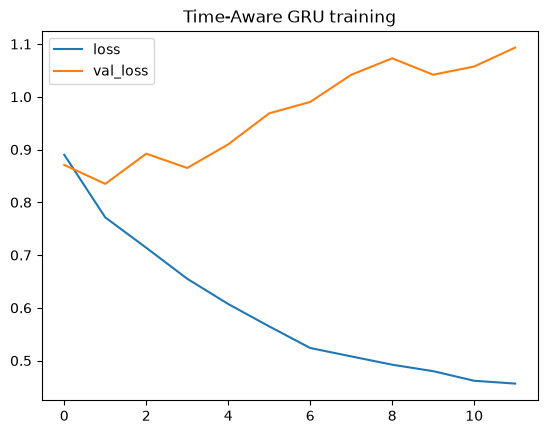

In [6]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(120, 18))
x = layers.GRU(64, reset_after=True)(inputs)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(4, activation="softmax")(x)
model = keras.Model(inputs, outputs, name="GRU_Elapsed_Time")
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
assert model.count_params() == 18340
model.summary()
soft_weights = {0:1.5295399750627603, 1:0.7522705172835694,
                2:1.148662739989314, 3:0.9770224004489462}
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=0.00001),
    keras.callbacks.ModelCheckpoint(str(BEST_MODEL), monitor="val_loss", save_best_only=True)
]
history = model.fit(train_seq, validation_data=val_seq, epochs=MAX_EPOCHS,
                    class_weight=soft_weights, callbacks=callbacks)
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
best_model = keras.models.load_model(BEST_MODEL)
sample, _ = val_seq[0]
np.testing.assert_allclose(model.predict(sample, verbose=0),
                           best_model.predict(sample, verbose=0), atol=1e-5)
print("Best epoch:", int(np.argmin(history.history["val_loss"])) + 1)
pd.DataFrame(history.history)[["loss", "val_loss"]].plot(title="Time-Aware GRU training")
plt.show()

## Validation evaluation and TCN comparison
Historical TCN results are reported references, not newly measured results: original 17-feature causal TCN accuracy 0.6191 / macro F1 0.6182; time-aware TCN accuracy 0.6738 / macro F1 0.6640. The time-aware TCN is the controlled architecture comparison. When its saved model/scaler/features are present, recompute predictions on identical keyed endpoints. Otherwise retain clearly labeled historical references only.

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
{'accuracy': 0.6494905873967548, 'macro_f1': 0.6324702905038655}
              precision    recall  f1-score   support

        Wake     0.5012    0.5845    0.5397      2084
       Light     0.6986    0.6341    0.6648     11002
        Deep     0.6481    0.7923    0.7130      4463
         REM     0.6290    0.5968    0.6125      6302

    accuracy                         0.6495     23851
   macro avg     0.6192    0.6519    0.6325     23851
weighted avg     0.6535    0.6495    0.6490     23851



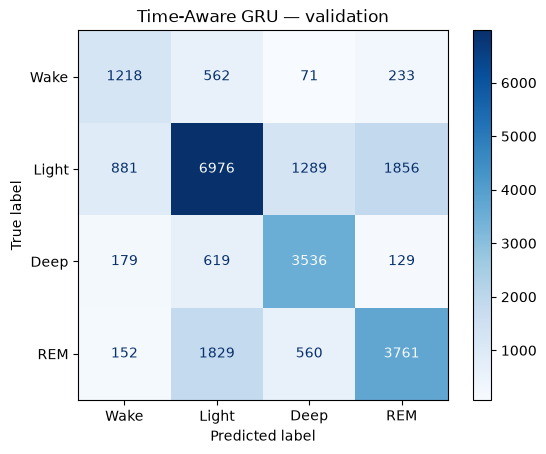

I0000 00:00:1794429438.420761     823 service.cc:154] XLA service 0x7051cc5e8920 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794429438.420784     823 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794429438.441230     823 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


59/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

I0000 00:00:1794429440.065976     823 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
GRU minus TCN: {'accuracy': -0.024317638673430952, 'macro_f1': -0.031577722703762134}


,model,source,accuracy,macro_f1
0,Time-Aware GRU,Measured this run,0.649491,0.632470
1,Original causal TCN (17 features),Historical rounded reference,0.619100,0.618200
2,Time-Aware TCN (18 features),Historical rounded reference,0.673800,0.664000
3,Time-Aware TCN (18 features),Recomputed same endpoints,0.673808,0.664048


,person,endpoints,accuracy,macro_f1,tcn_accuracy,tcn_macro_f1,macro_f1_change
0,Bidslab09,3354,0.622838,0.630938,0.628503,0.647793,-0.016855
1,Bidslab11,4642,0.636364,0.579023,0.636364,0.581693,-0.002670
2,Bidslab16,5362,0.719508,0.726239,0.752518,0.750674,-0.024434
3,Bidslab31,3437,0.636893,0.566981,0.682572,0.589172,-0.022191
4,Bidslab38,1935,0.667183,0.558398,0.675452,0.568742,-0.010344
5,Bidslab49,1575,0.686984,0.674721,0.700317,0.693286,-0.018565
6,Bidslab64,3546,0.571912,0.497104,0.625494,0.557167,-0.060062


In [7]:
LABELS = [0, 1, 2, 3]
STAGES = ["Wake", "Light", "Deep", "REM"]
y_true = y_val[val_seq.ends]
y_prob = best_model.predict(val_seq, verbose=1)
y_pred = y_prob.argmax(axis=1)
def metrics(actual, predicted):
    return {"accuracy":float(accuracy_score(actual, predicted)),
            "macro_f1":float(f1_score(actual, predicted, labels=LABELS, average="macro", zero_division=0))}
gru_metrics = metrics(y_true, y_pred)
print(gru_metrics)
report = classification_report(y_true, y_pred, labels=LABELS, target_names=STAGES, digits=4, zero_division=0)
print(report)
(OUTPUT_DIR / "classification_report.txt").write_text(report)
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
pd.DataFrame(cm, index=STAGES, columns=STAGES).to_csv(OUTPUT_DIR / "confusion_matrix.csv")
ConfusionMatrixDisplay(cm, display_labels=STAGES).plot(cmap="Blues", values_format="d")
plt.title("Time-Aware GRU — validation")
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()
predictions = endpoint_keys.copy()
predictions["actual"] = y_true
predictions["gru_predicted"] = y_pred
for k, stage in enumerate(STAGES):
    predictions["gru_probability_" + stage.lower()] = y_prob[:, k]
rows = [dict(model="Time-Aware GRU", source="Measured this run", **gru_metrics),
        dict(model="Original causal TCN (17 features)", source="Historical rounded reference", accuracy=.6191, macro_f1=.6182),
        dict(model="Time-Aware TCN (18 features)", source="Historical rounded reference", accuracy=.6738, macro_f1=.6640)]
tcn_paths = [DATA_DIR / s for s in ["sleep_tcn_120x18_elapsed_best.keras", "scaler_tcn_18.pkl", "features_tcn_18.pkl"]]
if RUN_TCN_COMPARISON and all(p.is_file() for p in tcn_paths):
    tcn_scaler = joblib.load(tcn_paths[1])
    assert list(joblib.load(tcn_paths[2])) == features_18
    np.testing.assert_allclose(tcn_scaler.mean_, scaler.mean_, atol=1e-10)
    np.testing.assert_allclose(tcn_scaler.scale_, scaler.scale_, atol=1e-10)
    tcn_seq = CausalWindowSequence(tcn_scaler.transform(val[features_18]).astype(np.float32), y_val, val, batch_size=BATCH_SIZE)
    np.testing.assert_array_equal(tcn_seq.ends, val_seq.ends)
    tcn = keras.models.load_model(tcn_paths[0])
    tcn_pred = tcn.predict(tcn_seq, verbose=1).argmax(axis=1)
    predictions["tcn_predicted"] = tcn_pred
    rows.append(dict(model="Time-Aware TCN (18 features)", source="Recomputed same endpoints", **metrics(y_true, tcn_pred)))
    print("GRU minus TCN:", {k:gru_metrics[k]-metrics(y_true, tcn_pred)[k] for k in gru_metrics})
else:
    print("Saved TCN comparison skipped: disabled or model/scaler/features unavailable.")
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
if PER_PERSON:
    person_rows = []
    for person, group in predictions.groupby("person"):
        row = dict(person=person, endpoints=len(group), **metrics(group.actual, group.gru_predicted))
        if "tcn_predicted" in group:
            tm = metrics(group.actual, group.tcn_predicted)
            row.update({"tcn_"+k:v for k,v in tm.items()})
            row["macro_f1_change"] = row["macro_f1"] - tm["macro_f1"]
        person_rows.append(row)
    per_person = pd.DataFrame(person_rows)
    display(per_person)
    per_person.to_csv(OUTPUT_DIR / "per_person_comparison.csv", index=False)

## Save reproducible inference artifacts
The best `.keras` model is already checkpointed. Keep it with the scaler and ordered feature list. Inference must reproduce these causal temporal features, elapsed time, scaling, and unmasked padding. Repeated validation experiments can overfit the seven validation participants; leave the test split untouched until final selection.

In [8]:
joblib.dump(scaler, OUTPUT_DIR / "scaler_gru_18.pkl")
joblib.dump(features_18, OUTPUT_DIR / "features_gru_18.pkl")
(OUTPUT_DIR / "features_gru_18.json").write_text(json.dumps(features_18, indent=2))
def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda:f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()
manifest = dict(seed=SEED, window=120, epoch_seconds=30, min_endpoint_position=19,
    padding="zero after scaling; no mask", elapsed_hours="(epoch - first observed epoch of night) / 120",
    features=features_18, class_weights=soft_weights, best_epoch=int(np.argmin(history.history["val_loss"]))+1,
    validation_endpoints=len(y_true), metrics=gru_metrics, parameters=best_model.count_params(),
    train_participants=sorted(train.person.unique().tolist()), val_participants=sorted(val.person.unique().tolist()),
    source_sha256={s:sha256(DATA_DIR / s) for s in ["train_temporal.csv", "val_temporal.csv"]},
    python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__)
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
loaded_scaler = joblib.load(OUTPUT_DIR / "scaler_gru_18.pkl")
np.testing.assert_allclose(loaded_scaler.transform(val[features_18]).astype(np.float32), X_val)
assert list(joblib.load(OUTPUT_DIR / "features_gru_18.pkl")) == features_18
print("Saved and verified:", OUTPUT_DIR.resolve())

Saved and verified: /home/yaser/ML_Projects/Capstone/artifacts_time_aware_gru_60min
